# Circ1PAT1R stable derivative for one parameter, without the LISA response

Compares the Fisher estimate of the uncertainty in `chi2` with the true 1D likelihood, for FEW's post-adiabatic model `Circ1PAT1R` (FEW >= 2.2). SEF uses the sky-averaged LISA sensitivity curve on $h_+$ and $h_\times$.

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import few
from few.waveform import Circ1PAT1R

from stableemrifisher.fisher import StableEMRIFisher
from stableemrifisher.utils import inner_product

use_gpu = False  # set to True to run on an NVIDIA GPU

if not use_gpu:
    # restrict FEW to its CPU backend
    cfg_set = few.get_config_setter(reset=True)
    cfg_set.enable_backends("cpu")

## Set up StableEMRIFisher

`evolve_primary=False` holds the primary's mass and spin fixed.

In [2]:
T = 0.1  # observation time, years
dt = 10.0  # sampling interval, seconds

sef = StableEMRIFisher(
    waveform_class=Circ1PAT1R,
    waveform_class_kwargs=dict(
        inspiral_kwargs=dict(
            evolve_primary=False,  # hold the primary's mass and spin fixed
            err=1e-11,  # trajectory integrator tolerance
        ),
    ),
    waveform_kwargs=dict(mode_selection_threshold=1e-5),
    T=T,
    dt=dt,
    deriv_type="stable",
    use_gpu=use_gpu,
)

No noise model or response wrapper provided.
Defaulting to the sky-averaged sensitivity curve


## Compute the Fisher element for `chi2`

The secondary spin `chi2` is passed through `add_param_args`.

Waveform Generated. SNR: 2785.364506003604
The step chosen for chi2 is the largest trial step (1.738e-03): the most stable step may lie outside the grid. Extend delta_range to larger steps.
  chi2       delta = 1.738e-03   relerr = 1.3e-08   (8 steps)              
Choosing step sizes: 100%|██████████| 8/8 [00:00<00:00, 10.01deriv/s]      


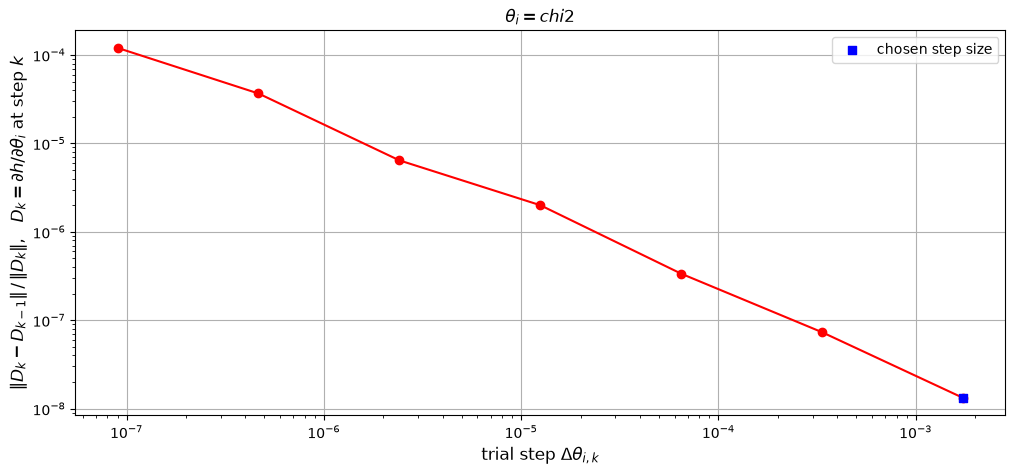

Computing Fisher   : 100%|██████████| 1/1 [00:00<00:00, 12.92deriv/s]
Calculated Fisher is positive-definite.
Fisher estimate: sigma(chi2) = 1.484e-03


In [3]:
wave_params = dict(
    m1=1e6,  # primary mass, solar masses
    m2=1e3,  # secondary mass, solar masses
    a=0.5,  # primary spin
    p0=16.0,  # initial orbital separation
    e0=0.0,  # not used by Circ1PAT1R
    xI0=1.0,  # not used by Circ1PAT1R
    dist=0.1,  # luminosity distance, Gpc
    qS=np.pi / 3,  # sky location, polar angle
    phiS=np.pi / 4,  # sky location, azimuthal angle
    qK=np.pi / 6,  # spin orientation, polar angle
    phiK=np.pi / 8,  # spin orientation, azimuthal angle
    Phi_phi0=1.0,  # initial azimuthal phase
    Phi_theta0=0.0,  # not used by Circ1PAT1R
    Phi_r0=0.0,  # not used by Circ1PAT1R
)
add_param_args = dict(chi2=0.9)  # secondary spin

param = "chi2"

Fisher = sef(
    wave_params,
    add_param_args=add_param_args,
    param_names=[param],
    der_order=4,
    Ndelta=8,
    stability_plot=True,
    stats_for_nerds=True,
)

sigma = 1 / np.sqrt(Fisher[0, 0])
print(f"Fisher estimate: sigma({param}) = {sigma:.3e}")

## Compare with the true likelihood

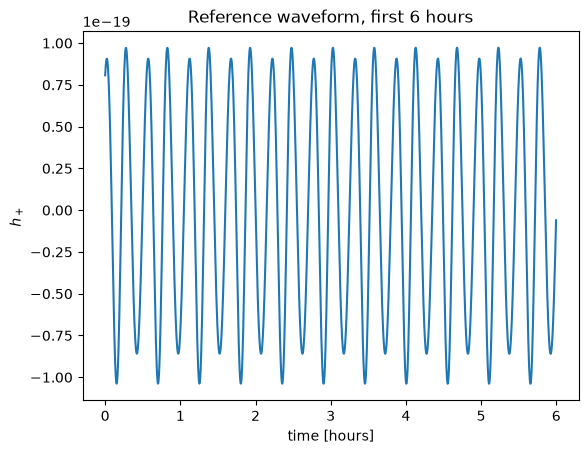

In [4]:
npad = sef.derivative.npad
N = sef.waveform.shape[-1]

reference = sef.waveform.copy()
reference[:, N - npad:] = 0.0

# plot the first 6 hours of the plus polarisation
n_show = int(6 * 3600 / dt)
time_hours = np.arange(n_show) * dt / 3600
plt.plot(time_hours, reference[0, :n_show].get() if use_gpu else reference[0, :n_show])
plt.xlabel("time [hours]")
plt.ylabel(r"$h_+$")
plt.title("Reference waveform, first 6 hours")
plt.show()

In [5]:
values = np.linspace(wave_params[param] - 4 * sigma, wave_params[param] + 4 * sigma, 50)

log_like = []
for value in tqdm(values, desc="Likelihood", file=sys.stdout):
    params = dict(sef.wave_params, **{param: value})  # includes chi2
    template = sef.derivative.generate(*params.values(), **sef.current_waveform_kwargs)
    template[:, N - npad:] = 0.0
    residual = reference - template
    log_like.append(-0.5 * inner_product(residual, residual, sef.PSD_funcs, dt, use_gpu=use_gpu))

likelihood = np.exp(np.array(log_like) - max(log_like))
gaussian = np.exp(-0.5 * ((values - wave_params[param]) / sigma) ** 2)

Likelihood: 100%|██████████| 50/50 [00:02<00:00, 20.58it/s]


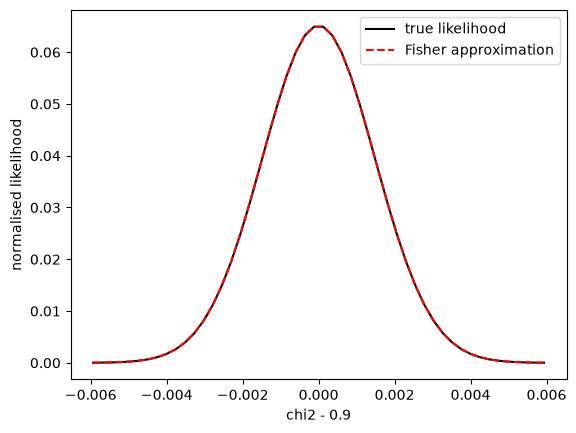

In [6]:
offset = values - wave_params[param]
plt.plot(offset, likelihood / likelihood.sum(), "k", label="true likelihood")
plt.plot(offset, gaussian / gaussian.sum(), "r--", label="Fisher approximation")
plt.xlabel(f"{param} - {wave_params[param]}")
plt.ylabel("normalised likelihood")
plt.legend()
plt.show()